# Grids

Grids are general types of plots that allow you to map plot types to rows and columns of a grid, this helps you create similar plots separated by features.

In [1]:
import seaborn as sns
import numpy as numpy
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
iris = sns.load_dataset('iris')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
iris.species.unique()

<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

## PairGrid

Pairgrid is a subplot grid for plotting pairwise relationships in a dataset.

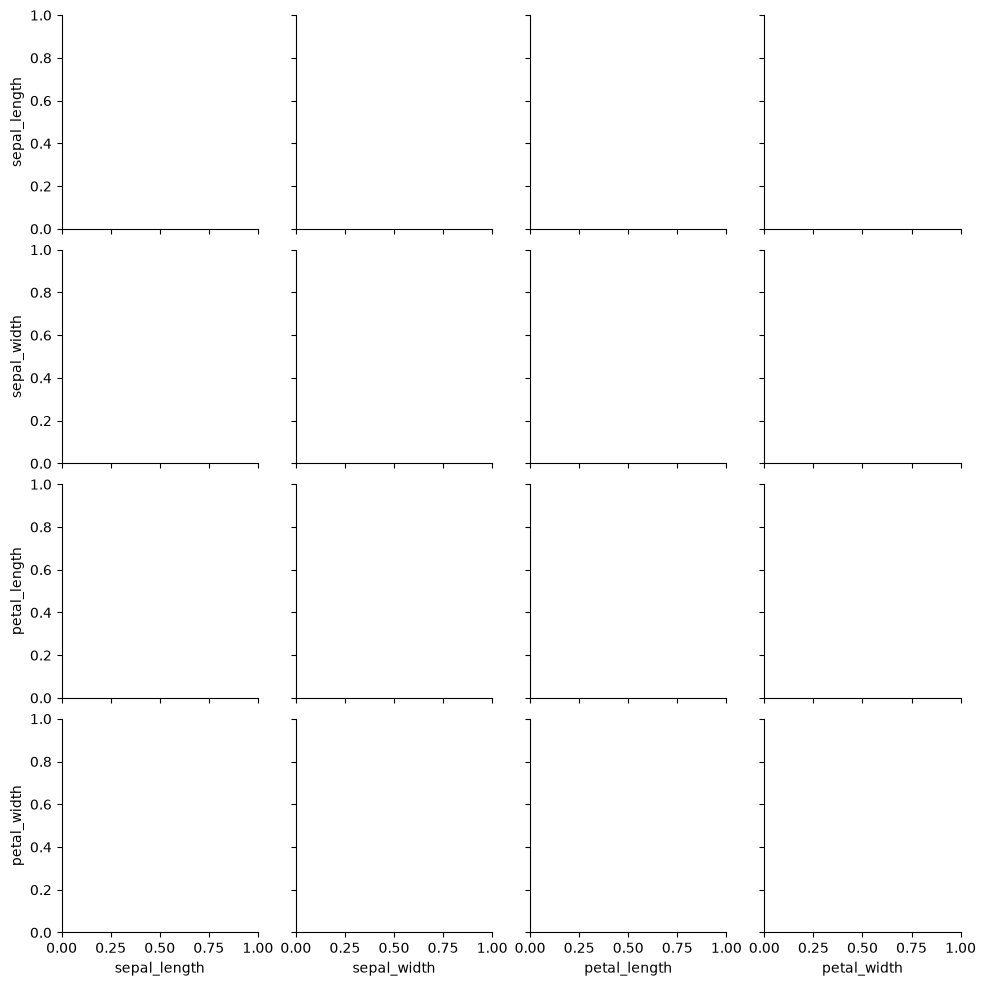

In [4]:
sns.PairGrid(iris)

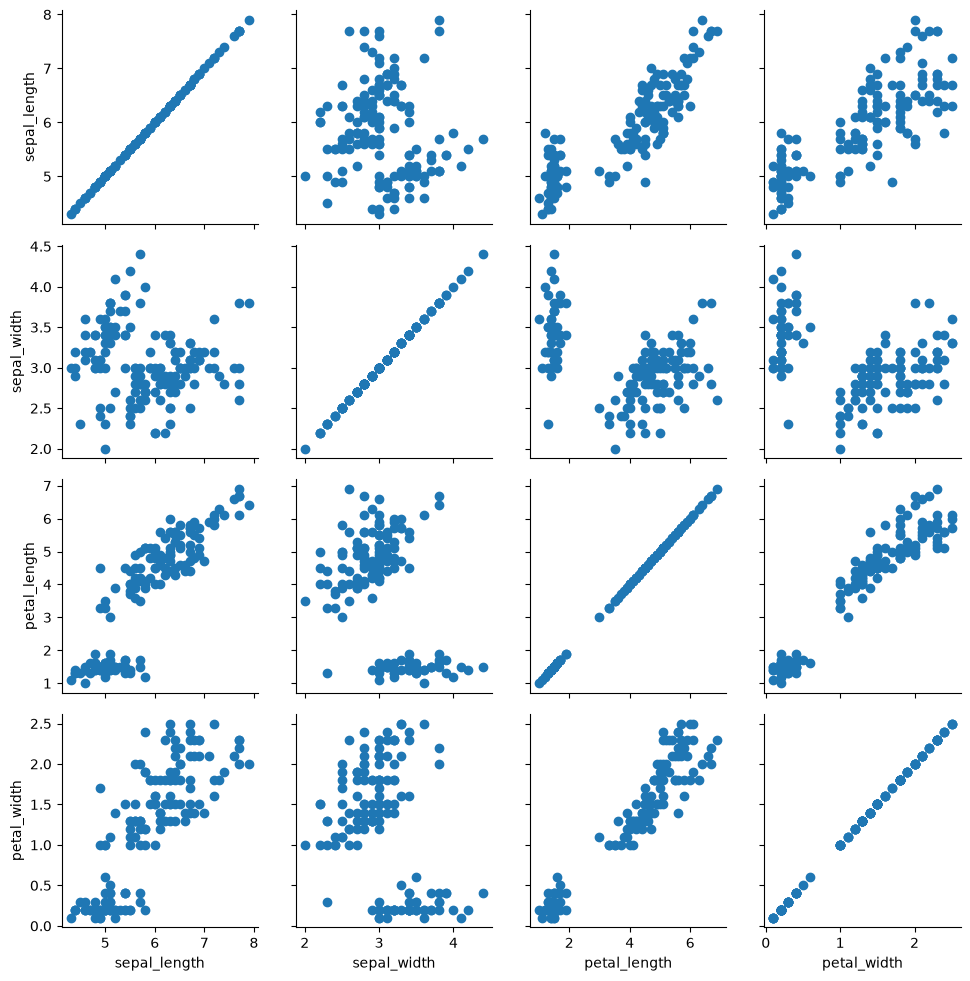

In [5]:
g= sns.PairGrid(iris)
g.map(plt.scatter)

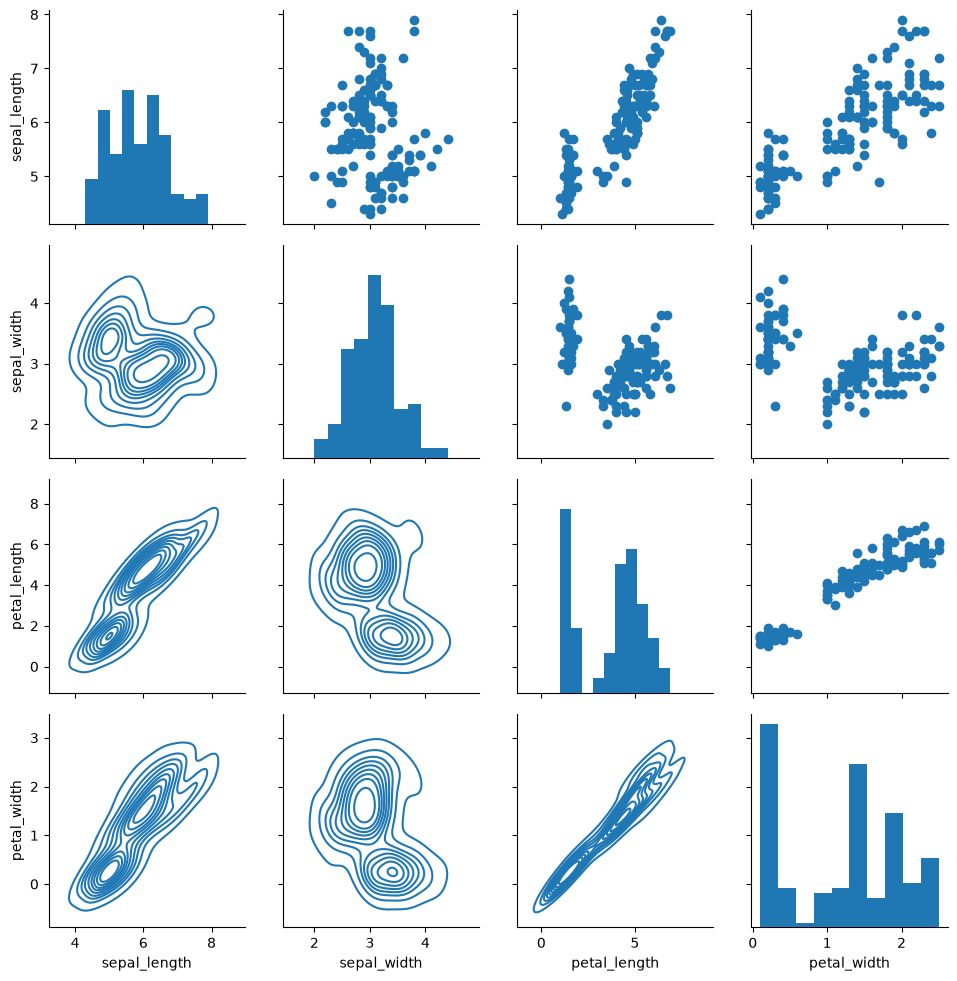

In [6]:
g = sns.PairGrid(iris)
g.map_diag(plt.hist)
g.map_upper(plt.scatter)
g.map_lower(sns.kdeplot)

## pairplot

pairplot is a simpler version of PairGrid (you'll use quite often)

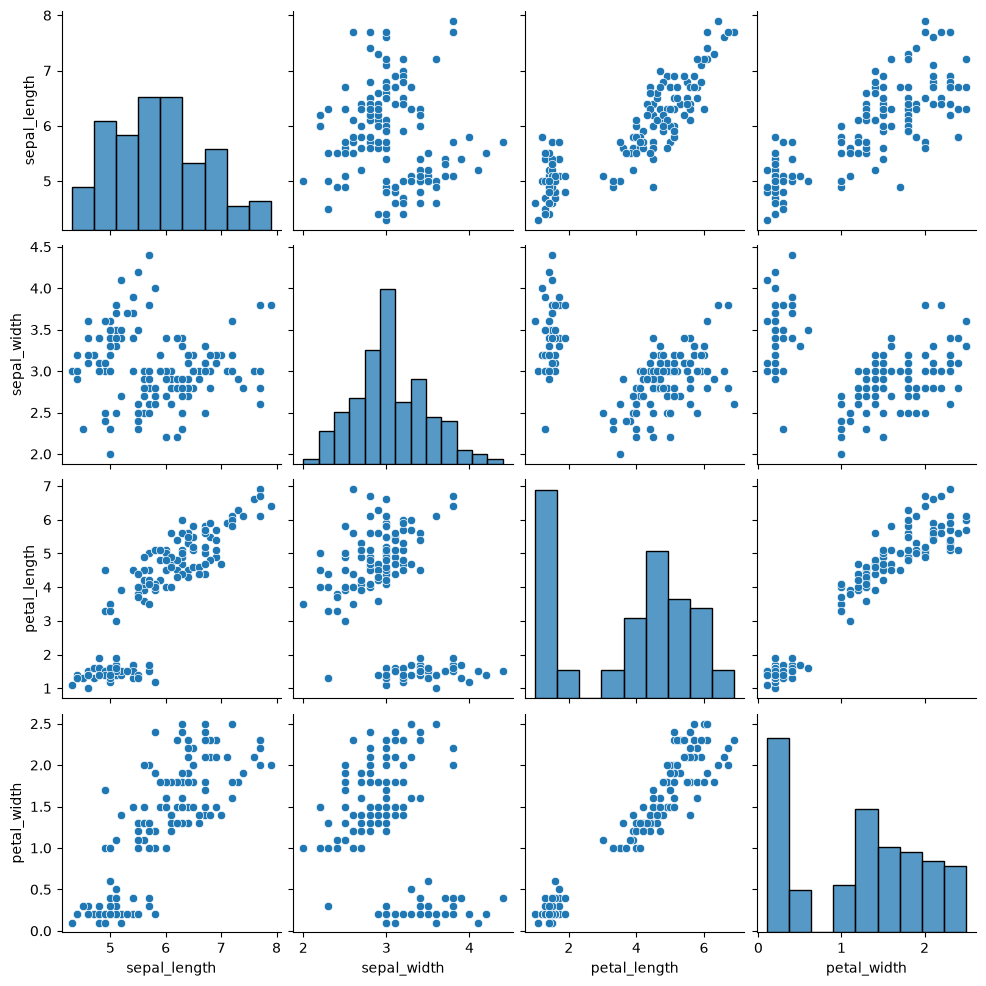

In [7]:
sns.pairplot(iris)

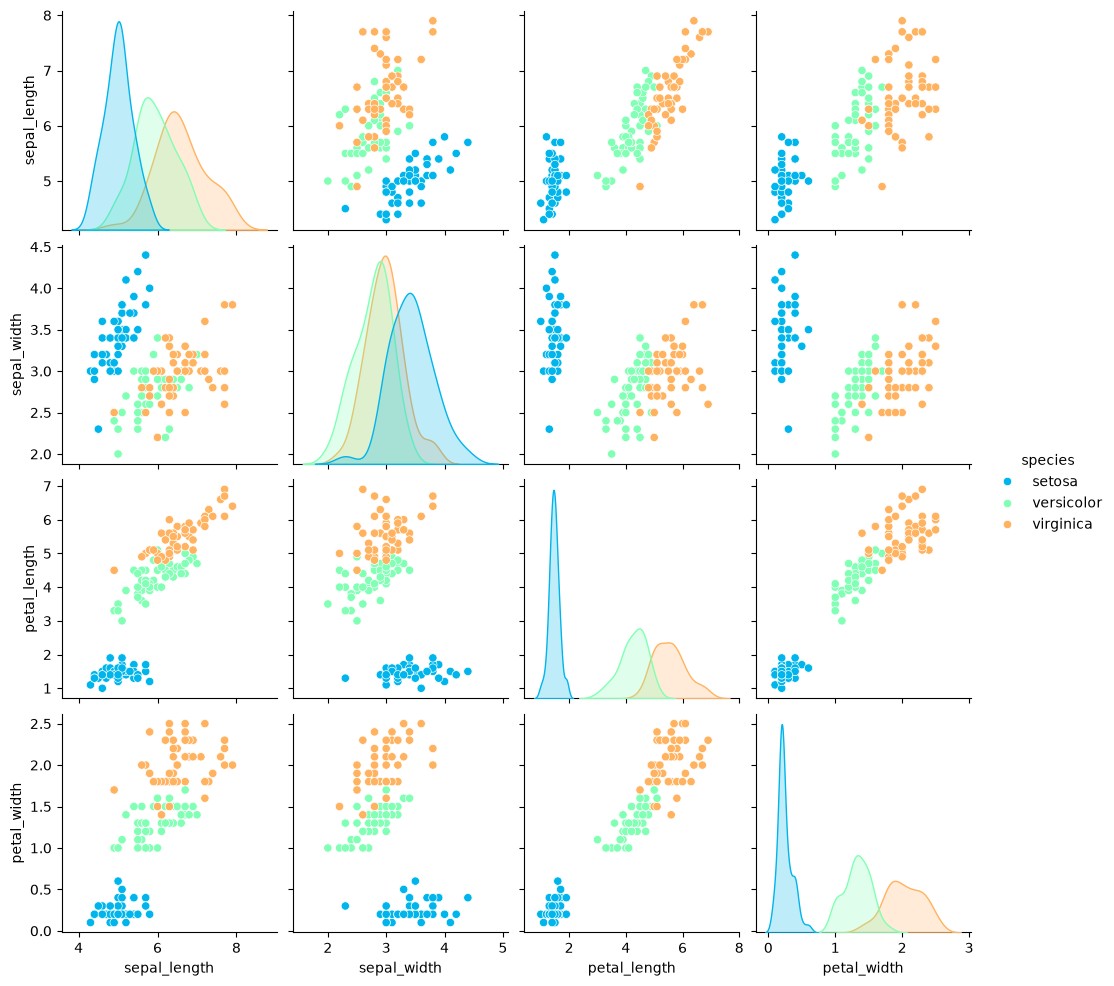

In [8]:
sns.pairplot(data=iris,hue='species',palette='rainbow')

## Facet Grid

FacetGrid is the general way to create grids of plots based off of a feature:

In [9]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


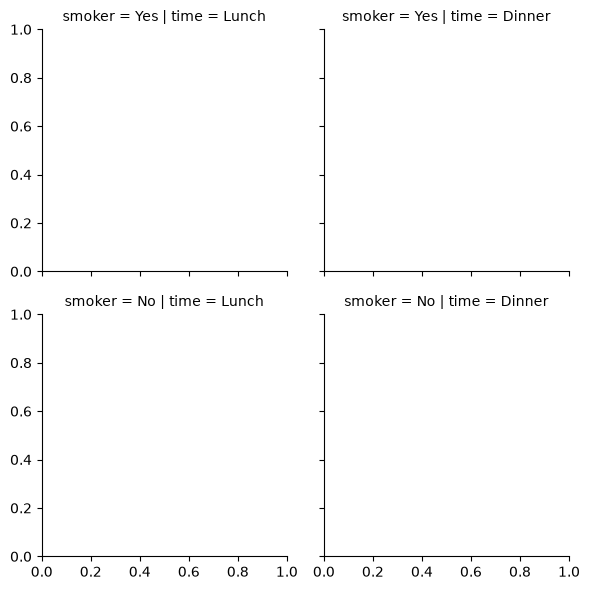

In [10]:
sns.FacetGrid(tips, col='time',row='smoker')

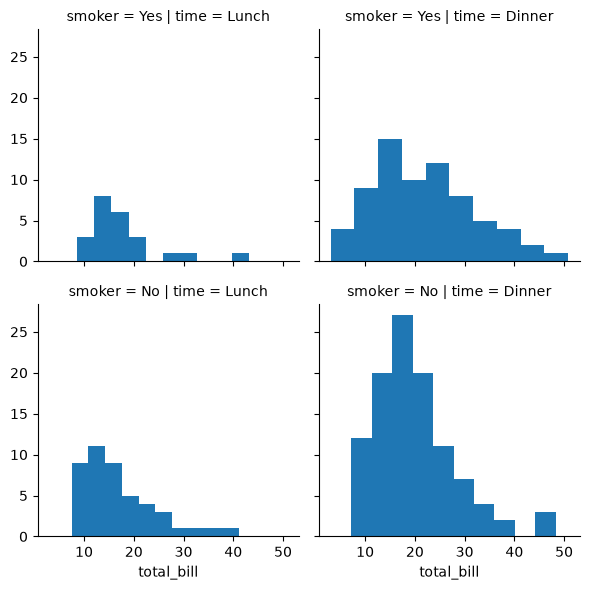

In [11]:
g = sns.FacetGrid(tips, col='time',row='smoker')
g = g.map(plt.hist, "total_bill")

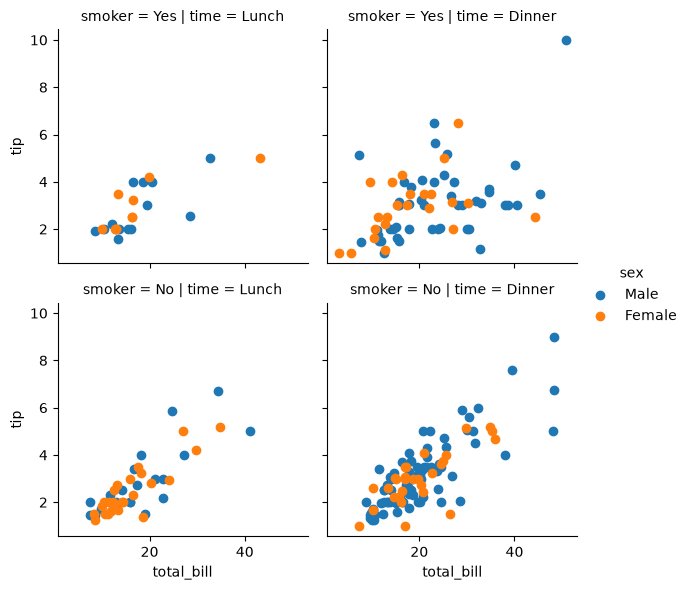

In [12]:
g = sns.FacetGrid(tips, col="time",  row="smoker",hue='sex')

g = g.map(plt.scatter,"total_bill","tip").add_legend()

## JointGrid

JointGrid is the general version for jointplot() type grids, for a quick example:

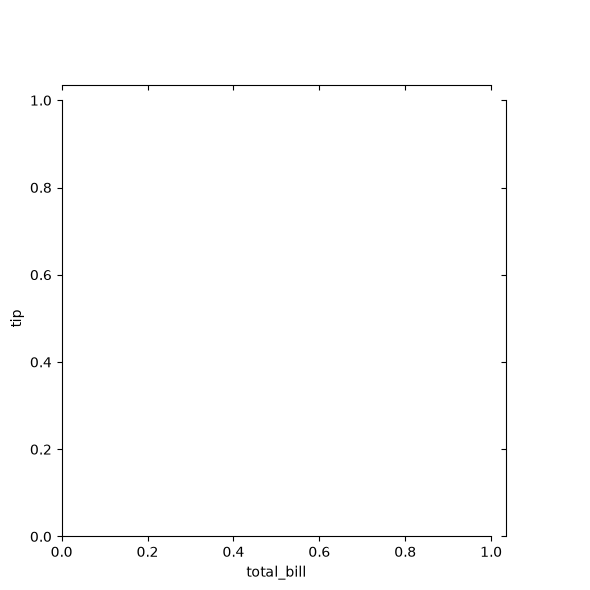

In [13]:
g = sns.JointGrid(x="total_bill", y="tip", data=tips)

c:\Users\KK67\contoso\venv\Lib\site-packages\seaborn\axisgrid.py:1886: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  func(self.x, **orient_kw_x, **kwargs)
c:\Users\KK67\contoso\venv\Lib\site-packages\seaborn\axisgrid.py:1892: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  func(self.y, **orient_kw_y, **kwargs)


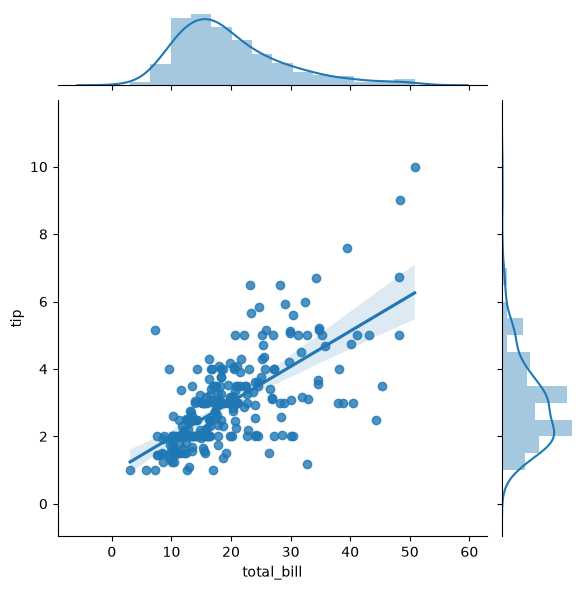

In [14]:
g = sns.JointGrid(x="total_bill", y="tip", data=tips)
g = g.plot(sns.regplot, sns.distplot)

# Regression Plots

Seaborn has many built-in capabilities for regression plots, however we won't really discuss regression until the machine learning section of the course, so we will only cover the **lmplot()** function for now.

**lmplot** allows you to display linear models, but it also conveniently allows you to split up those plots based off of features, as well as coloring the hue based off of features.

Let's explore how this works:

In [15]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


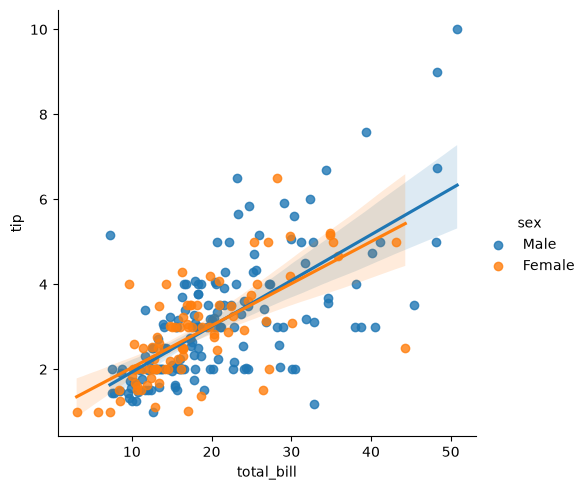

In [17]:
sns.lmplot(x='total_bill',y='tip', data=tips, hue='sex')

### Working with Markers

lmplot kwargs get passed through to **regplot** which is a more general form of lmplot(). regplot has a scatter_kws parameter that gets passed to plt.scatter. So you want to set the s parameter in that dictionary, which corresponds (a bit confusingly) to the squared markersize. In other words you end up passing a dictionary with the base matplotlib arguments, in this case, s for size of a scatter plot. In general, you probably won't remember this off the top of your head, but instead reference the documentation.

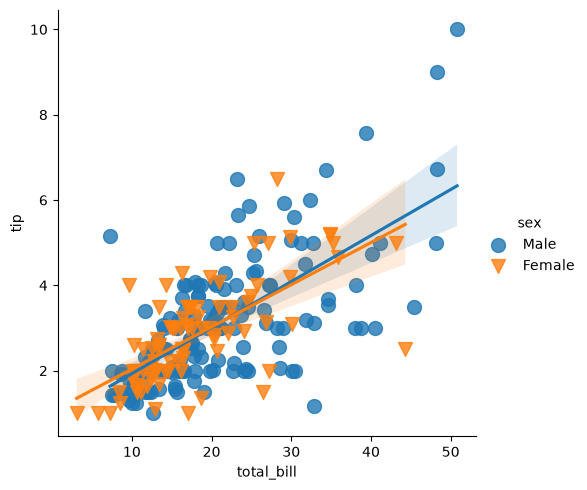

In [19]:
sns.lmplot(x='total_bill',y='tip', data=tips, hue='sex', markers=['o','v'], scatter_kws={'s':100})

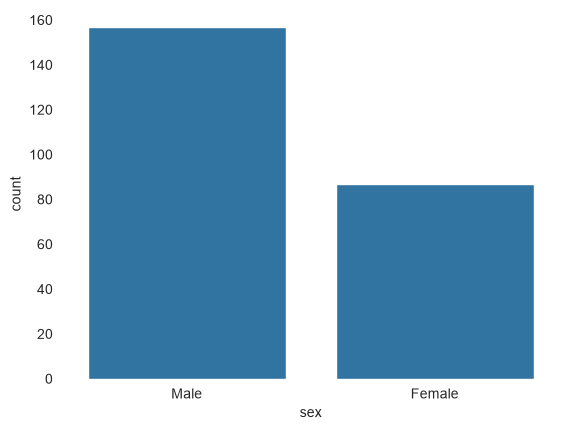

In [22]:
sns.set_style('white')
sns.countplot(x='sex',data=tips)
sns.despine(left=True, bottom=True)

<Axes: xlabel='sex', ylabel='count'>

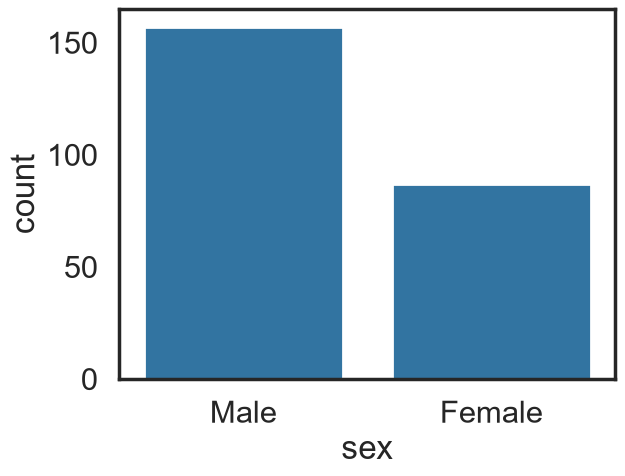

In [23]:
sns.set_context('poster')
sns.countplot(x='sex',data=tips)

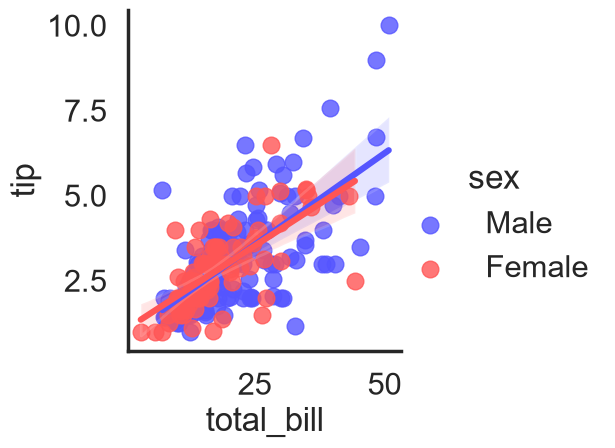

In [24]:
sns.lmplot(data=tips,x='total_bill',y='tip',hue='sex',palette='seismic')